In [15]:
from google.colab import drive
import os
from pyspark.sql import SparkSession
from pyspark.ml.feature import VectorAssembler, StandardScaler
from pyspark.ml.clustering import KMeans
from pyspark.ml.evaluation import ClusteringEvaluator
from pyspark.sql.functions import col, substring, expr, trim, when, regexp_replace, length, row_number, round
from pyspark.sql.types import DoubleType, LongType
from pyspark.ml.linalg import Vectors, VectorUDT
from pyspark.sql.functions import udf
from pyspark.sql import functions as F
from pyspark.sql.window import Window
import matplotlib.pyplot as plt


# Mount Google Drive and define and verify the path to the FIFA 18 dataset stored in Drive
drive.mount('/content/drive')
data_path = "/content/drive/MyDrive/CompleteDataset_saved.csv"
os.path.exists(data_path)

# Create Spark session
spark = SparkSession.builder.appName("FIFA18_KMeans").getOrCreate()


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [16]:
# Load FIFA 18 dataset into Spark DataFrame
df = spark.read.csv(data_path, header=True, inferSchema=True)

# Inspect the data
df.printSchema()
df.show(5)

# Inspect what is at the end of the Strings in column Value.
df.select(
    substring(col("Value"), -1, 1).alias("last_char")
).groupBy("last_char").count().orderBy("count", ascending=False).show()

# Inspect what is at the end of the Strings in column Wage.
df.select(
    substring(col("Wage"), -1, 1).alias("last_char")
).groupBy("last_char").count().orderBy("count", ascending=False).show()

root
 |-- Unnamed: 0: integer (nullable = true)
 |-- Name: string (nullable = true)
 |-- Age: integer (nullable = true)
 |-- Photo: string (nullable = true)
 |-- Nationality: string (nullable = true)
 |-- Flag: string (nullable = true)
 |-- Overall: integer (nullable = true)
 |-- Potential: integer (nullable = true)
 |-- Club: string (nullable = true)
 |-- Club Logo: string (nullable = true)
 |-- Value: string (nullable = true)
 |-- Wage: string (nullable = true)
 |-- Special: integer (nullable = true)
 |-- Acceleration: string (nullable = true)
 |-- Aggression: string (nullable = true)
 |-- Agility: string (nullable = true)
 |-- Balance: string (nullable = true)
 |-- Ball control: string (nullable = true)
 |-- Composure: string (nullable = true)
 |-- Crossing: string (nullable = true)
 |-- Curve: string (nullable = true)
 |-- Dribbling: string (nullable = true)
 |-- Finishing: string (nullable = true)
 |-- Free kick accuracy: string (nullable = true)
 |-- GK diving: string (nullable =

In [17]:

# ---------- PREPROCESSING THE FEATURES USED FOR CLUSTERING ------------

# List of the features for clustering
feature_cols = [
    "Acceleration", "Ball control", "Composure", "Dribbling", "Finishing", "Long passing", "Short passing", "Reactions", "Stamina", "Volleys"
]

# Make a DataFrame consisting of the selected clustering attributes + ID (Unnamed: 0)
df_selected = df.select(["Unnamed: 0"] + feature_cols)


# Checks which lenght of value exists is in each column.
for col_name in feature_cols:
    print(f"Character lengths in {col_name}")
    df_selected.select(length(col(col_name)).alias("len")).distinct().show()

# Keep at most the first two characters and trim whitespace
for c in feature_cols:
    df_selected = df_selected.withColumn(
        c,
        trim(substring(col(c), 1, 2))
    )

# Convert attribute values from string to DoubleType
for c in feature_cols:
    df_selected = df_selected.withColumn(
        c,
        col(c).cast(DoubleType())
    )

# Remove rows with missing values
df_clean = df_selected.dropna()

# Assemble features in feature_cols into a single vector column ("features"), as required by Spark's K-means implementation
assembler = VectorAssembler(inputCols=feature_cols, outputCol="features")
df_vec = assembler.transform(df_clean)

# Standardize these features so that all attributes contribute equally to distance calculations
scaler = StandardScaler(
    inputCol="features",
    outputCol="scaledFeatures",
    withMean=True,
    withStd=True
)

scaler_model = scaler.fit(df_vec)
df_clustering = scaler_model.transform(df_vec)


Character lengths in Acceleration
+---+
|len|
+---+
|  5|
|  4|
|  2|
+---+

Character lengths in Ball control
+---+
|len|
+---+
|  1|
|  5|
|  4|
|  2|
+---+

Character lengths in Composure
+---+
|len|
+---+
|  1|
|  5|
|  4|
|  2|
+---+

Character lengths in Dribbling
+---+
|len|
+---+
|  1|
|  5|
|  4|
|  2|
+---+

Character lengths in Finishing
+---+
|len|
+---+
|  1|
|  5|
|  4|
|  2|
+---+

Character lengths in Long passing
+---+
|len|
+---+
|  1|
|  5|
|  4|
|  2|
+---+

Character lengths in Short passing
+---+
|len|
+---+
|  5|
|  4|
|  2|
+---+

Character lengths in Reactions
+---+
|len|
+---+
|  5|
|  4|
|  2|
+---+

Character lengths in Stamina
+---+
|len|
+---+
|  5|
|  4|
|  2|
+---+

Character lengths in Volleys
+---+
|len|
+---+
|  1|
|  5|
|  4|
|  2|
+---+



k=5, silhouette=0.3169
k=6, silhouette=0.3302
k=7, silhouette=0.3057
k=8, silhouette=0.3020
k=9, silhouette=0.3060
k=10, silhouette=0.2838
k=11, silhouette=0.2939
k=12, silhouette=0.2781
k=13, silhouette=0.2762
k=14, silhouette=0.2641
k=15, silhouette=0.2507


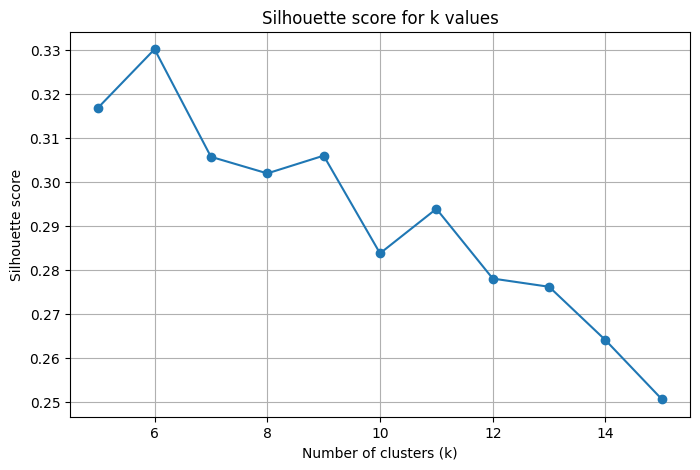

In [18]:
# Create a fixed random subset using a fixed seed for reproducibility and comparable results.
df_silhouette = df_clustering.sample(
    withReplacement=False,
    fraction=0.25,
    seed=42
)

# Store silhouette scores for each tested value of k
silhouette_scores = []

# Train K-means models for different numbers of clusters (k)
for k in range(5, 16):
    kmeans = KMeans(
        k=k,
        featuresCol="scaledFeatures",
        seed=42
    )
    # Fit the K-means model on the silhouette subset
    model = kmeans.fit(df_silhouette)
    # Assign cluster labels to the subset
    predictions = model.transform(df_silhouette)

# Create a silhouette evaluator that operates on column scaledFeatures
    evaluator = ClusteringEvaluator(
        featuresCol="scaledFeatures",
        metricName="silhouette",
        distanceMeasure="squaredEuclidean"
    )

    score = evaluator.evaluate(predictions)
    silhouette_scores.append((k, score))

for k, score in silhouette_scores:
    print(f"k={k}, silhouette={score:.4f}")


# Create a plot
k_values = [x[0] for x in silhouette_scores]
scores = [x[1] for x in silhouette_scores]

plt.figure(figsize=(8, 5))
plt.plot(k_values, scores, marker='o')
plt.xlabel("Number of clusters (k)")
plt.ylabel("Silhouette score")
plt.title("Silhouette score for k values")
plt.grid(True)
plt.show()


In [19]:
# ------------------ FINAL K-MEANS CLUSTERING ------------------

# Initialize K-means model
kmeans = KMeans(
    k=11,
    featuresCol="scaledFeatures",
    seed=42
)

# Fit the model on the full dataset
kmeans_model = kmeans.fit(df_clustering)

# Assign cluster labels to each player
df_kmeans = kmeans_model.transform(df_clustering)


In [20]:
# Show how many players are in each cluster
df_kmeans.groupBy("prediction").count().orderBy("prediction").show()

+----------+-----+
|prediction|count|
+----------+-----+
|         0| 1232|
|         1|  901|
|         2| 2022|
|         3| 1399|
|         4| 2451|
|         5| 1942|
|         6| 1137|
|         7| 1535|
|         8| 2639|
|         9| 1469|
|        10| 1254|
+----------+-----+



In [21]:
# -------------- PREPROCESSING THE VALUE AND WAGE FEATURES ----------------

df_value_wage = (
    df
    .withColumn(
        "Value_clean",
        when(col("Value").endswith("K"),
             regexp_replace(col("Value"), "[^0-9.]", "").cast(DoubleType()) * 1000
        ).when(col("Value").endswith("M"),
             regexp_replace(col("Value"), "[^0-9.]", "").cast(DoubleType()) * 1_000_000
        ).otherwise(
             regexp_replace(col("Value"), "[^0-9.]", "").cast(DoubleType())
        )
    )
    .withColumn(
        "Wage_clean",
        when(col("Wage").endswith("K"),
             regexp_replace(col("Wage"), "[^0-9.]", "").cast(DoubleType()) * 1000
        ).otherwise(
             regexp_replace(col("Wage"), "[^0-9.]", "").cast(DoubleType())
        )
    )
    .filter((col("Value_clean") > 0) & (col("Wage_clean") > 0))
    .select(
        col("Unnamed: 0"),
        "Name",
        "Value_clean",
        "Wage_clean"
    )
)

# Join on ID column
df_kmeans_full = (
    df_kmeans
    .join(df_value_wage, on="Unnamed: 0", how="inner")
)



In [22]:
df_kmeans_full.printSchema()


root
 |-- Unnamed: 0: integer (nullable = true)
 |-- Acceleration: double (nullable = true)
 |-- Ball control: double (nullable = true)
 |-- Composure: double (nullable = true)
 |-- Dribbling: double (nullable = true)
 |-- Finishing: double (nullable = true)
 |-- Long passing: double (nullable = true)
 |-- Short passing: double (nullable = true)
 |-- Reactions: double (nullable = true)
 |-- Stamina: double (nullable = true)
 |-- Volleys: double (nullable = true)
 |-- features: vector (nullable = true)
 |-- scaledFeatures: vector (nullable = true)
 |-- prediction: integer (nullable = false)
 |-- Name: string (nullable = true)
 |-- Value_clean: double (nullable = true)
 |-- Wage_clean: double (nullable = true)



In [23]:
# Inspect the wage and value data
from pyspark.sql.functions import min, max, avg

df_kmeans_full.agg(
    min("Value_clean").alias("Value_min"),
    max("Value_clean").alias("Value_max"),
    avg("Value_clean").alias("Value_mean"),
    min("Wage_clean").alias("Wage_min"),
    max("Wage_clean").alias("Wage_max"),
    avg("Wage_clean").alias("Wage_mean")
).show()


+---------+---------+-----------------+--------+--------+------------------+
|Value_min|Value_max|       Value_mean|Wage_min|Wage_max|         Wage_mean|
+---------+---------+-----------------+--------+--------+------------------+
|  10000.0|   1.23E8|2419841.466854725|  1000.0|565000.0|11711.537376586743|
+---------+---------+-----------------+--------+--------+------------------+



In [24]:
# --------------- FIND ONE STAR PLAYER PER CLUSTER -----------------

# Window: partition by cluster, order by Value descending
w = Window.partitionBy("prediction").orderBy(col("Value_clean").desc())

# Select the single highest-value player per cluster
cluster_stars = (
    df_kmeans_full
    .withColumn("rank", row_number().over(w))
    .filter(col("rank") == 1)
    .select(
        "prediction",
        col("Unnamed: 0"),
        "Name",
        "scaledFeatures",
        "Value_clean",
        "Wage_clean"
    )
    .orderBy("prediction")
)

# Show the star player for each cluster
cluster_stars.show()


+----------+----------+------------+--------------------+-----------+----------+
|prediction|Unnamed: 0|        Name|      scaledFeatures|Value_clean|Wage_clean|
+----------+----------+------------+--------------------+-----------+----------+
|         0|       160|     B. Dost|[-0.7111116378180...|      2.7E7|   28000.0|
|         1|         6|      De Gea|[-0.5098646081456...|     6.45E7|  215000.0|
|         2|         2|      Neymar|[1.97218209114681...|     1.23E8|  280000.0|
|         3|      2971|   T. Šunjić|[-1.1136056971627...|  3600000.0|   31000.0|
|         4|        70|   R. Varane|[0.83178225633674...|     4.65E7|  175000.0|
|         5|       706|  Jorge Meré|[0.29512351054376...|      1.2E7|   26000.0|
|         6|      2180|Yoon Bo Sang|[-2.1869231887487...|  5500000.0|    3000.0|
|         7|      4069|  A. Morelos|[0.49637054021613...|  4300000.0|   30000.0|
|         8|       931| M. Phillips|[1.56968803180208...|     1.05E7|   68000.0|
|         9|      2286|  Rúb

In [25]:
cluster_stars.printSchema()

root
 |-- prediction: integer (nullable = false)
 |-- Unnamed: 0: integer (nullable = true)
 |-- Name: string (nullable = true)
 |-- scaledFeatures: vector (nullable = true)
 |-- Value_clean: double (nullable = true)
 |-- Wage_clean: double (nullable = true)



In [26]:
# --------- FIND 20 MOST SIMILAR PLAYERS TO EACH CLUSTER STAR -------

# Select relevant features and rename them to prevent name collision
cluster_stars_vec = (
    cluster_stars
    .select(
        col("prediction").alias("cluster"),
        col("Unnamed: 0").alias("star_id"),
        col("scaledFeatures").alias("starFeatures"),
        col("Name").alias("starName")
    )
)

# Join all players with their cluster star
df_candidates = (
    df_kmeans_full
    .join(
        cluster_stars_vec,
        df_kmeans_full.prediction == cluster_stars_vec.cluster,
        how="inner"
    )
)

# Function to compute euclidean distance
def euclidean_distance(v1, v2):
    return float(Vectors.squared_distance(v1, v2)) ** 0.5

# Compute the distance between players and their cluster star
distance_udf = udf(euclidean_distance, DoubleType())
df_with_distance = df_candidates.withColumn(
    "distance",
    distance_udf(col("scaledFeatures"), col("starFeatures"))
)

w = Window.partitionBy("prediction").orderBy(col("distance").asc())

# Select the 20 players closest to each star
top_similar = (
    df_with_distance
    .filter(col("Unnamed: 0") != col("star_id"))  # exclude the star by ID
    .withColumn("rank", row_number().over(w))
    .filter(col("rank") <= 20)
)

top_similar.select(
    "prediction",
    "starName",
    col("Name").alias("playerName"),
    "Value_clean",
    "Wage_clean",
    "distance"
).orderBy("prediction", "rank")


DataFrame[prediction: int, starName: string, playerName: string, Value_clean: double, Wage_clean: double, distance: double]

In [27]:
# Find the 2 players among the 20 with the shortest distance to star
w_closest = Window.partitionBy("prediction").orderBy(col("distance").asc())

closest_2 = (
    top_similar
    .withColumn("rank_closest", row_number().over(w_closest))
    .filter(col("rank_closest") <= 2)
    .withColumn("role", F.lit("Closest sub"))
)

# Find the 2 players among the 20 with the lowest wage
w_cheapest = Window.partitionBy("prediction").orderBy(col("Wage_clean").asc())

cheapest_2 = (
    top_similar
    .withColumn("rank_cheapest", row_number().over(w_cheapest))
    .filter(col("rank_cheapest") <= 2)
    .withColumn("role", F.lit("Cheapest sub"))
)

# Add column distance and role to the stars rows.
stars_final = (
    cluster_stars
    .withColumn("distance", F.lit(0.0))
    .withColumn("role", F.lit("Star"))
)

# Create a df of stars with their closest and cheapest substitutes and show the results.
final_table = (
    stars_final
    .select("prediction", "Name", "Value_clean", "Wage_clean", "distance", "role")
    .unionByName(
        closest_2.select("prediction", "Name", "Value_clean", "Wage_clean", "distance", "role")
    )
    .unionByName(
        cheapest_2.select("prediction", "Name", "Value_clean", "Wage_clean", "distance", "role")
    )
    .orderBy("prediction", "distance", "role")
)


final_table.show(100)


+----------+-----------------+-----------+----------+-------------------+------------+
|prediction|             Name|Value_clean|Wage_clean|           distance|        role|
+----------+-----------------+-----------+----------+-------------------+------------+
|         0|          B. Dost|      2.7E7|   28000.0|                0.0|        Star|
|         0|      N. Petersen|  8000000.0|   33000.0| 1.6980781584976519| Closest sub|
|         0|      S. Kießling|  4800000.0|   56000.0| 1.7330561646972984| Closest sub|
|         0|   C. Wondolowski|  1200000.0|    7000.0|  2.073059709930459|Cheapest sub|
|         0|        D. Lafata|  1400000.0|    1000.0| 2.0760053144285684|Cheapest sub|
|         1|           De Gea|     6.45E7|  215000.0|                0.0|        Star|
|         1|        H. Lloris|      3.8E7|  165000.0| 0.9474211232768117| Closest sub|
|         1|         Fabricio|      1.0E7|   48000.0| 1.4877130505786238| Closest sub|
|         1|       K. Vermeer|  6500000.0| 

In [28]:
# ---- MEAN AND MAX DISTANCE TO STAR PER CLUSTER FOR EVAL----

# Compute mean and maximum Euclidean distance to the star for each cluster
distance_stats = (
    df_with_distance
    .groupBy("prediction")
    .agg(
        F.mean("distance").alias("mean_distance_to_star"),
        F.max("distance").alias("max_distance_to_star")
    )
    .orderBy("prediction")
)

distance_stats.show(truncate=False)


+----------+---------------------+--------------------+
|prediction|mean_distance_to_star|max_distance_to_star|
+----------+---------------------+--------------------+
|0         |3.516717985614372    |5.031741799298748   |
|1         |3.9769442707573974   |5.552453037940264   |
|2         |3.550821935648827    |5.924355825383719   |
|3         |2.4751421585419306   |4.301598916955149   |
|4         |2.615602758230618    |4.437424414194305   |
|5         |2.8637341376982466   |4.395728685671564   |
|6         |2.476697595070894    |5.444466825555697   |
|7         |2.1187367698709565   |3.920263013814885   |
|8         |2.048000646162044    |3.4183359236262776  |
|9         |2.023622787934036    |3.913266566606462   |
|10        |3.6031455297489523   |5.684304710444222   |
+----------+---------------------+--------------------+

